# Tutorial to run benchmark examples 
This notebook demonstrates how to run the benchmark problems in the paper *A Latent-Space
Framework for Stress-Based Multi-Material Topology Optimization*.  
The entire workflow is described from start to finish: the material database, its principal
components, the latent dimension that follows, the trained decoder, the problem
being solved, and the result.

These were run on a machine with a 12th Gen Intel Core i7-12700KF, 20 logical cores CPU on Windows 11.
Approximate run times, excluding setup:

| | Domain | Materials | Latent | Objective | Constraints | Elements | Iterations | Run time |
|---|---|---|---|---|---|---|---|---|
| L-bracket | 2D benchmark against Banh et al. | 3 | 2D | p-norm stress | volume fraction per material | 12,825 | 300 | 15 min |
| U-bracket | 2D, slot corner stress riser | 6 | 2D | p-norm failure factor | mass | 9,001 | 350 | 19 min |
| Supported beam | 3D octant model | 8 | 2D | p-norm failure factor | mass | 25,748 | 350 | 38 min |
| Airplane bracket | 3D half model | 20 | 3D | p-norm failure factor | mass and cost | 49,676 | 300 | 65 min |


## SETUP

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, ".")

from utils import project_paths, records, figures, tables

ROOT = project_paths.bootstrap()

import numpy as np
import torch
import run_io
from ExamplesPureStructural import getMMTOProblemPureStructural
from materialEncoder import MaterialEncoder
from MainPureStructural import run_topopt, Z0InitMethod, BetaScheduleScheme

print(ROOT)

c:\Akshat\TopologyOptimizer\LSR-Stress-MMTO


## 1. Choose an example

Set `CHOICE` to one of:

| `CHOICE` | example | problem |
|---|---|---|
| 1 | L-bracket | benchmark against Banh et al., volume fraction per material |
| 2 | U-bracket | six materials, mass constrained |
| 3 | beam | eight materials, octant model |
| 4 | Airplane bracket | twenty alloys, mass and cost constrained |

You may also modify the `relative_filter_radius` and the `material_filter_radius` parameters to change the topological and material feature sizes respectively.

In [2]:
# ==================================================
# Optimization Settings
# ==================================================

RELATIVE_FILTER_RADIUS = 5.0
MATERIAL_FILTER_RADIUS = 5.0

PNORM_EXPONENT = 6.0

MAX_ITERATIONS = 300

BETA_SCHEME = BetaScheduleScheme.PAPER

## 2. The material database

This is the database the VAE is trained on. Each column is a material attribute. 
The VAE embeds these materials in a continuous latent space.

In [3]:
mesh, mat_prop, bc, body_force, to_params, vae_params = \
    getMMTOProblemPureStructural()

xlsx = to_params.MaterialsExcelFile

mat_encoder = MaterialEncoder(vae_params)
mat_encoder.readExcel(xlsx)

tables.materials(mat_encoder, "StructuralProblem")

Non-design elements: 684 / 3240
[RectangularBeam] elems=3240 elem_size=[11.111 11.111 12.5  ] fixed_nodes=100 load_nodes=225
Intrinsic dimension estimate (participation ratio): 1.514
PCA explained variance ratio: [7.83203363e-01 2.16796651e-01 1.44553129e-15]


,material,Density [kg/m^3],Youngs_Modulus [Pa],Yield_Strength [Pa]
,A,1,100,100
,B,1.2,160,140
,C,1.4,140,180
,D,1.6,200,220
,E,1.8,120,260
,F,2,180,300


## 3. Latent dimension

The dimension of the latent space is determined using PCA as a heuristic.

PCA on the normalized attributes gives one eigenvalue per direction. The
effective dimension $d_{\mathrm{eff}}$ is the participation ratio of those
eigenvalues, a non-integer count of how many directions carry real variance.
The latent dimension is $n_z = \lceil d_{\mathrm{eff}} \rceil$.

In [4]:
tables.pca(mat_encoder)

The database has 3 attributes, but its effective dimension is d_eff = 1.51: the first principal component alone carries 78.3% of the variance. A latent space of n_z = 2 is enough to represent it.

Principal components of the material database
component  eigenvalue  explained variance %  cumulative %
---------  ----------  --------------------  ------------
1          0.3289      78.32                 78.32       
2          0.09105     21.68                 100.00      
3          6.071e-16   0.00                  100.00      

quantity                    value 
--------------------------  ------
effective dimension, d_eff  1.5142
latent dimension, n_z       2

## 4. The problem

Red arrows are the applied load, black markers the fixed and symmetry degrees
of freedom, drawn on the meshed design domain.

Non-design elements: 684 / 3240
[RectangularBeam] elems=3240 elem_size=[11.111 11.111 12.5  ] fixed_nodes=100 load_nodes=225


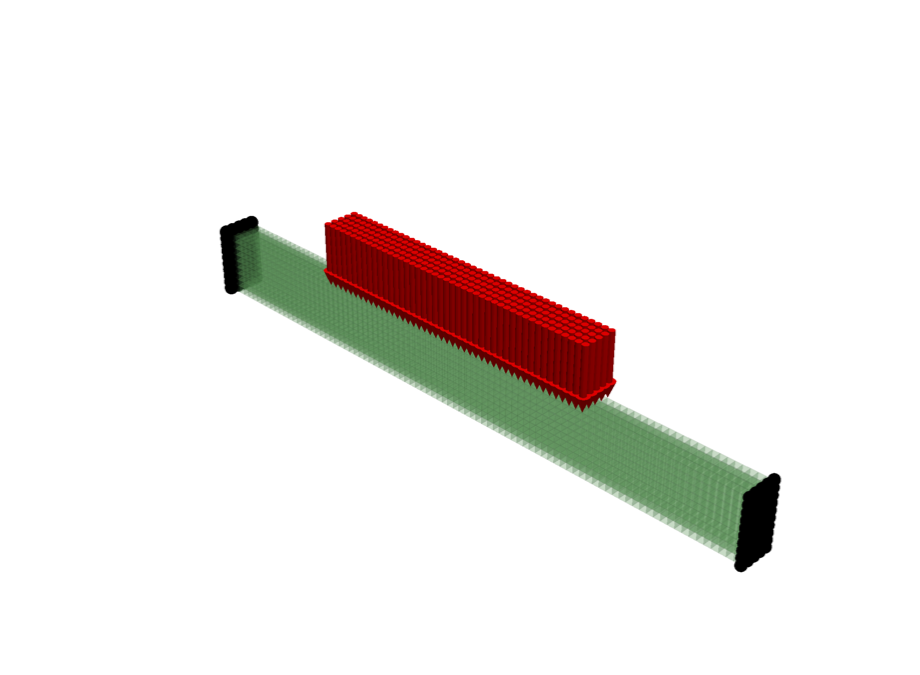

In [5]:
import pyvista as pv
pv.set_jupyter_backend("static")
pv.global_theme.window_size = [1400, 1050]
pv.global_theme.anti_aliasing = "ssaa"
_ = figures.boundary_conditions(size=(920, 675), zoom=0.9)


## 5. The decoder

Set `USE_REFERENCE_VAE = True` to load the VAE used for this benchmark in the
paper. Set it to `False` to train one from scratch.

A freshly trained VAE gives a different latent space, and so a different
design. The run loads whichever network this cell prepares, so the
reconstruction error below is for the decoder it uses.

In [6]:
import os

USE_REFERENCE_VAE = True

if USE_REFERENCE_VAE:
    net = xlsx.replace(".xlsx", ".nt")        # the network shipped with the database
    mat_encoder.loadAutoencoderFromFile(net)
    print(f"loaded {net}")
else:
    os.makedirs("results", exist_ok=True)
    net = "results/UserProblem_trained.nt"
    torch.manual_seed(1234)
    mat_encoder.trainAutoencoder(
        vae_params.numEpochs, vae_params.klFactor, net,
        vae_params.learningRate, vae_params.maxAttributeErrorPercent)
    print(f"trained a fresh network, saved to {net}")

loaded ./1-PureStructural/MaterialDataPureStructural/6Materials_AF_3Attr.nt


### How faithfully the decoder reproduces the database

Every real material is encoded to its latent point and decoded back. The error reported in the table below
is the difference between the decoded normalized attribute and the real normalized attribute from the database for that material. It measures how much the
embedding distorts the catalogue.

In [7]:
tables.encoding_errors(mat_encoder)

attribute,median error %,max error %
Density,0.1001,0.7001
Youngs_Modulus,0.2602,0.8192
Yield_Strength,0.0995,0.6942


## 6. Run

The settings below are the ones reported in the paper. 
`run_io.WRITE_FILES = True` saves the result of this run to the `results` folder.

In [8]:
run_io.WRITE_FILES = False

run_topopt(
    save_dir="results/UserProblem",
    saveNet=net,
    use_pretrained_vae=True,

    relative_filter_radius=RELATIVE_FILTER_RADIUS,
    material_filter_radius=MATERIAL_FILTER_RADIUS,
    pnorm_exponent=PNORM_EXPONENT,
    maxIterations=MAX_ITERATIONS,
    rel_conv_tol=1e-7,

    # distance-to-material penalty
    use_penalization=True,
    gamma_init=1e-3,
    gamma_factor=1.1,
    gamma_max=10,
    penalty_start_iter=0,
    distance_penalty_disable_after_iter=250,
    use_dynamic_gamma_scheduling=True,

    # latent smoothing
    use_z_smoothing=True,
    z_smoothing_weight=1e-4,
    z_smoothing_disable_after_iter=250,

    # Heaviside Projection
    use_heaviside_projection=True,
    beta_schedule_scheme=BETA_SCHEME,
    eta_proj=0.5,

    z0_init_method=Z0InitMethod.ORIGIN,
    snap_to_real_material=False,
    use_constant_poissons_ratio=False,
    constant_poissons_ratio=0.3,
    use_continuation=False,
    binarize_topology=True,
    verbose=True,
)

run = records.from_payload(
    run_io.LAST_RUN,
    descriptor="User STL run"
)
print(run.descriptor)

Non-design elements: 684 / 3240
[RectangularBeam] elems=3240 elem_size=[11.111 11.111 12.5  ] fixed_nodes=100 load_nodes=225
[SWEEP] nDOFDesired=12000  RelativeFilterRadius=5.0  MaterialFilterRadius=5.0  P=6.0
Intrinsic dimension estimate (participation ratio): 1.514
PCA explained variance ratio: [7.83203363e-01 2.16796651e-01 1.44553129e-15]
Loading pre-trained autoencoder from file: ./1-PureStructural/MaterialDataPureStructural/6Materials_AF_3Attr.nt
----------------------------------------
Attribute                     Max % Error
----------------------------------------
Density                          0.700116
Youngs_Modulus                   0.819224
Yield_Strength                   0.694156
----------------------------------------
Solver: PARDISO
Number of DOF: 13650
Using latent dimension: 2
Creating filter...
-------------- Iteration 0 -----------------
Percentage grey elements (x_phys): 100.00% | beta=1, eta=0.5
[STRESS DIAG] Iter    1 | active violations = 0/0 (0.000%) | all

## 7. The result

In [9]:
tables.summary(run)

quantity,value
example,UserProblem
run,User STL run
iterations,301
elements,3240
solid elements,1103 (34.0%)
latent dimension,2
materials available,6
materials used,2
"objective, Φp",64427.7266
max failure factor,0.2278


### Optimized design

Coloured by material after binarization.

Non-design elements: 684 / 3240
[RectangularBeam] elems=3240 elem_size=[11.1110 11.1110 12.5000] fixed_nodes=100 load_nodes=225


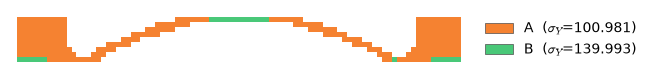

In [10]:
_=figures.design(run)

### Latent field

Black stars are the real materials, red points the converged latent coordinates
of the solid elements. Points sitting on a star are elements that resolved onto
a real material; points between them have not.

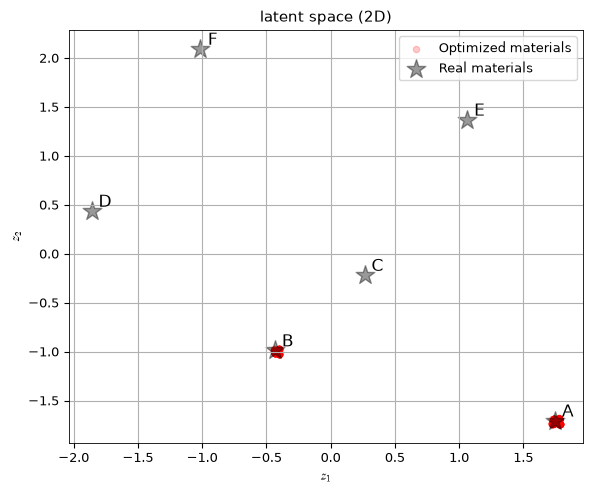

In [11]:
_=figures.latent_scatter(run)

### Convergence

The objective on the left axis, each constraint on the right as a fraction of
its budget.

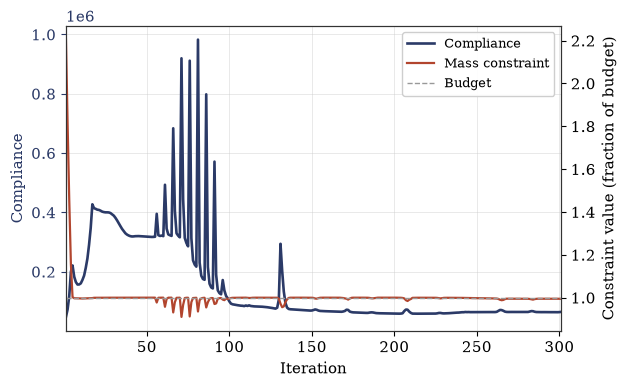

In [12]:
_=figures.convergence(run)